<a href="https://colab.research.google.com/github/KartikVerma8/Yulu-Hypothesis-Testing-Analysis/blob/main/Yulu_Hypothesis_Testing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Yulu Hypothesis Testing

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
#

In [ ]:
data = pd.read_csv('/content/Yulu.txt')
data.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


# Business/Company Background

Yulu is an Indian micro-mobility service provider offering shared electric vehicles for daily commuting. The company wants to understand the factors affecting demand for its shared electric cycles.

# Business Problem

Yulu has experienced a decline in revenue and wants to identify the variables that significantly influence the demand for shared electric cycles and understand how well these variables explain demand.

# Solving Business Case

# Step-1: Column Profiling

In [ ]:
data.shape

(10886, 12)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    10886 non-null  object 
 1   season      10886 non-null  int64  
 2   holiday     10886 non-null  int64  
 3   workingday  10886 non-null  int64  
 4   weather     10886 non-null  int64  
 5   temp        10886 non-null  float64
 6   atemp       10886 non-null  float64
 7   humidity    10886 non-null  int64  
 8   windspeed   10886 non-null  float64
 9   casual      10886 non-null  int64  
 10  registered  10886 non-null  int64  
 11  count       10886 non-null  int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 1020.7+ KB


## My Analysis:
The datetime column needs to be converted from object datatype to datetime datatype.

In [ ]:
data['datetime'] = pd.to_datetime(data['datetime'])

In [ ]:
categorical_cols = ['season', 'holiday', 'workingday', 'weather']

for col in categorical_cols:
    data[col] = data[col].astype('category')

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   datetime    10886 non-null  datetime64[ns]
 1   season      10886 non-null  category      
 2   holiday     10886 non-null  category      
 3   workingday  10886 non-null  category      
 4   weather     10886 non-null  category      
 5   temp        10886 non-null  float64       
 6   atemp       10886 non-null  float64       
 7   humidity    10886 non-null  int64         
 8   windspeed   10886 non-null  float64       
 9   casual      10886 non-null  int64         
 10  registered  10886 non-null  int64         
 11  count       10886 non-null  int64         
dtypes: category(4), datetime64[ns](1), float64(3), int64(4)
memory usage: 723.7 KB


In [ ]:
df = data.copy()

# Checking for the range of data/time-period within which data lies

In [ ]:
df['datetime'].min(), df['datetime'].max()

(Timestamp('2011-01-01 00:00:00'), Timestamp('2012-12-19 23:00:00'))

# My Analysis:
The dataset contains records from 1 January 2011 to 19 December 2012, covering almost two years of observations.

# Checking for null values

In [ ]:
df.isnull().sum()

,0
datetime,0
season,0
holiday,0
workingday,0
weather,0
temp,0
atemp,0
humidity,0
windspeed,0
casual,0


In [ ]:
df.isnull().sum().sum() # The dataset contains no missing values in any of the columns. Therefore, no missing-value treatment is required.

np.int64(0)

# Statistical summary

In [ ]:
df.describe()

,datetime,temp,atemp,humidity,windspeed,casual,registered,count
count,10886,10886.00000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000
mean,2011-12-27 05:56:22.399411968,20.23086,23.655084,61.886460,12.799395,36.021955,155.552177,191.574132
min,2011-01-01 00:00:00,0.82000,0.760000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2011-07-02 07:15:00,13.94000,16.665000,47.000000,7.001500,4.000000,36.000000,42.000000
50%,2012-01-01 20:30:00,20.50000,24.240000,62.000000,12.998000,17.000000,118.000000,145.000000
75%,2012-07-01 12:45:00,26.24000,31.060000,77.000000,16.997900,49.000000,222.000000,284.000000
max,2012-12-19 23:00:00,41.00000,45.455000,100.000000,56.996900,367.000000,886.000000,977.000000
std,NaN,7.79159,8.474601,19.245033,8.164537,49.960477,151.039033,181.144454


# My analysis:
The std value for the datetime column is shown as NaN because standard deviation is not directly calculated for datetime values in this statistical summary.

#Unique Values

In [ ]:
df.nunique()

,0
datetime,10886
season,4
holiday,2
workingday,2
weather,4
temp,49
atemp,60
humidity,89
windspeed,28
casual,309


# My Analysis:
The nunique() function shows the number of unique values present in each column. Categorical variables such as season, holiday, workingday, and weather have a limited number of unique categories, while datetime contains a unique timestamp for each observation.

In [ ]:
df.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


In [ ]:
for col in ['season', 'holiday', 'workingday', 'weather']:
    print(f"\n{col}:")
    print(df[col].value_counts(normalize = True)*100)


season:
season
4    25.114826
2    25.105640
3    25.105640
1    24.673893
Name: proportion, dtype: float64

holiday:
holiday
0    97.14312
1     2.85688
Name: proportion, dtype: float64

workingday:
workingday
1    68.087452
0    31.912548
Name: proportion, dtype: float64

weather:
weather
1    66.066507
2    26.033437
3     7.890869
4     0.009186
Name: proportion, dtype: float64


# My Analysis:
Season: The observations are almost evenly distributed across all four seasons. Winter accounts for 25.11%, Summer for 25.11%, Fall for 25.11%, and Spring for 24.67% of the observations. This indicates that the dataset provides a fairly balanced representation of bike-rental records across different seasons.

Holiday: 97.14% of the observations occur on non-holidays, while only 2.86% occur on holidays. This shows that the dataset contains considerably more regular-day observations than holiday observations.

Working Day: 68.09% of the observations occur on working days, while 31.91% occur on non-working days. Thus, the dataset has more observations for regular working days.

Weather: Clear/Few clouds/Partly cloudy conditions account for 66.07% of the observations, followed by Mist + Cloud conditions (26.03%) and Light Snow/Light Rain conditions (7.89%). Heavy Rain/Ice Pellets/Thunderstorm/Mist/Snow/Fog conditions account for only 0.01% of observations, indicating that this weather category is extremely rare in the dataset.

# Univariate Analysis — Continuous Variables

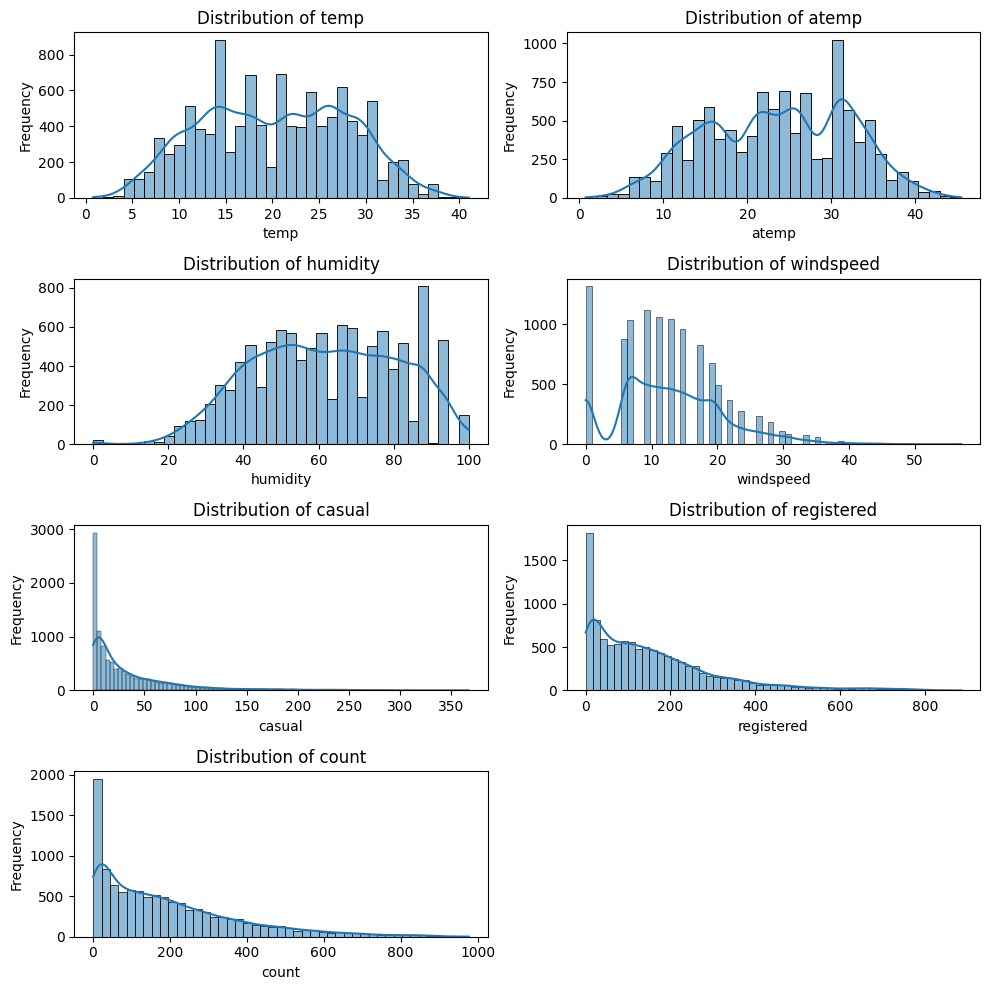

In [ ]:
continuous_cols = [
    'temp', 'atemp', 'humidity',
    'windspeed', 'casual', 'registered', 'count'
]

fig, axes = plt.subplots(4, 2, figsize=(10, 10))

for col, ax in zip(continuous_cols, axes.flatten()):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')

axes[-1, -1].axis('off')

plt.tight_layout()
plt.show()

# My Analysis:

The distributions of temperature (temp) and feeling temperature (atemp) are relatively spread across their respective ranges. Humidity is distributed across a broad range, while windspeed is positively skewed with most observations concentrated at lower values. Casual, registered, and total rental counts are strongly right-skewed, with most observations concentrated at lower values and a long tail toward higher values. These distributions indicate that the rental-count variables are not normally distributed.

# Univariate Analysis — Categorical Variables

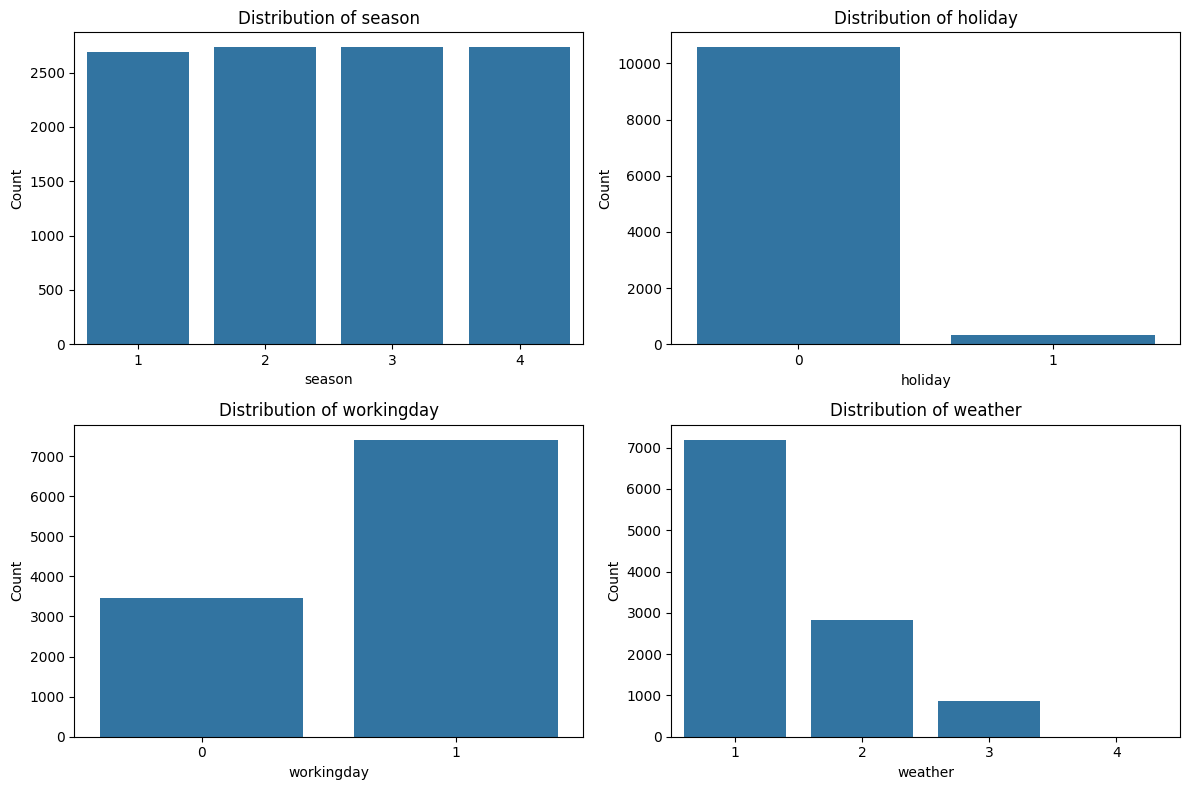

In [ ]:
categorical_cols = ['season', 'holiday', 'workingday', 'weather']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, ax in zip(categorical_cols, axes.flatten()):
    sns.countplot(x=col, data=df, ax=ax)
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Count')

plt.tight_layout()
plt.show()

# My Analysis:

The observations are fairly evenly distributed across the four seasons, with each season having a similar number of observations. Most observations are non-holidays, while holiday observations represent a much smaller proportion of the dataset. Working-day observations are substantially higher than non-working-day observations. Weather 1 is the most frequent weather condition, followed by Weather 2 and Weather 3, while Weather 4 is extremely rare with only one observation.

# Checking for outliers

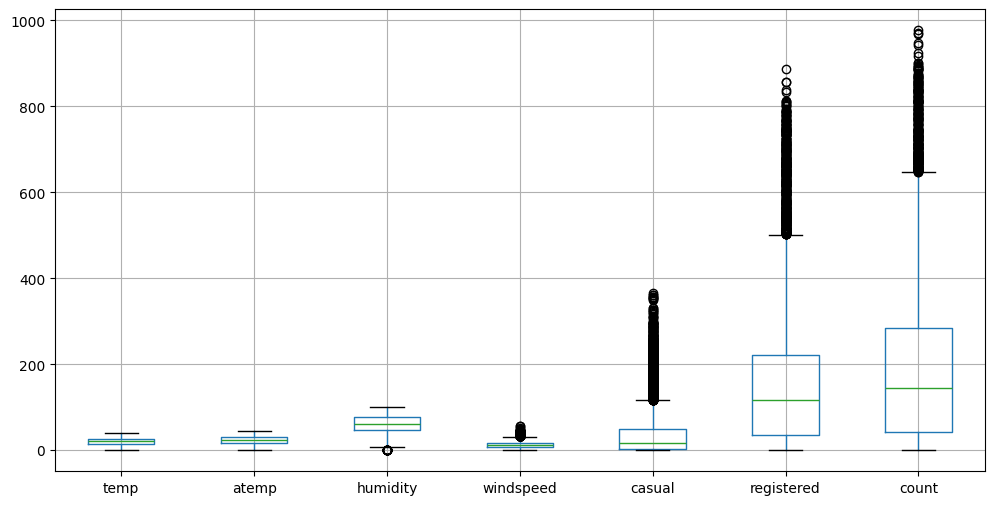

In [ ]:
df[['temp', 'atemp', 'humidity', 'windspeed',
    'casual', 'registered', 'count']].boxplot(figsize=(12,6))
plt.show()

# Detecting Outliers : IQR Method

In [ ]:
numerical_cols = ['temp', 'atemp', 'humidity', 'windspeed',
                  'casual', 'registered', 'count']

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    print(f"{col}: {len(outliers)} outliers")

temp: 0 outliers
atemp: 0 outliers
humidity: 22 outliers
windspeed: 227 outliers
casual: 749 outliers
registered: 423 outliers
count: 300 outliers


# Detecting Outliers: Percentage

In [ ]:
for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    percentage = len(outliers) / len(df) * 100

    print(f"{col}: {len(outliers)} outliers ({percentage:.2f}%)")

temp: 0 outliers (0.00%)
atemp: 0 outliers (0.00%)
humidity: 22 outliers (0.20%)
windspeed: 227 outliers (2.09%)
casual: 749 outliers (6.88%)
registered: 423 outliers (3.89%)
count: 300 outliers (2.76%)


# My Analysis:
I used the IQR method to identify potential outliers in the numerical variables. There were no outliers in temp and atemp. Only a small number were found in humidity (0.20%) and windspeed (2.09%). The rental-related variables showed more potential outliers, with casual at 6.88%, registered at 3.89%, and count at 2.76%.

The detected outliers were retained because they may represent genuine periods of unusually high or low rental demand rather than data-entry errors. Removing these observations could distort the actual demand pattern. Therefore, the outliers were identified and evaluated but not removed.

# Correlation Analysis  Heatmap

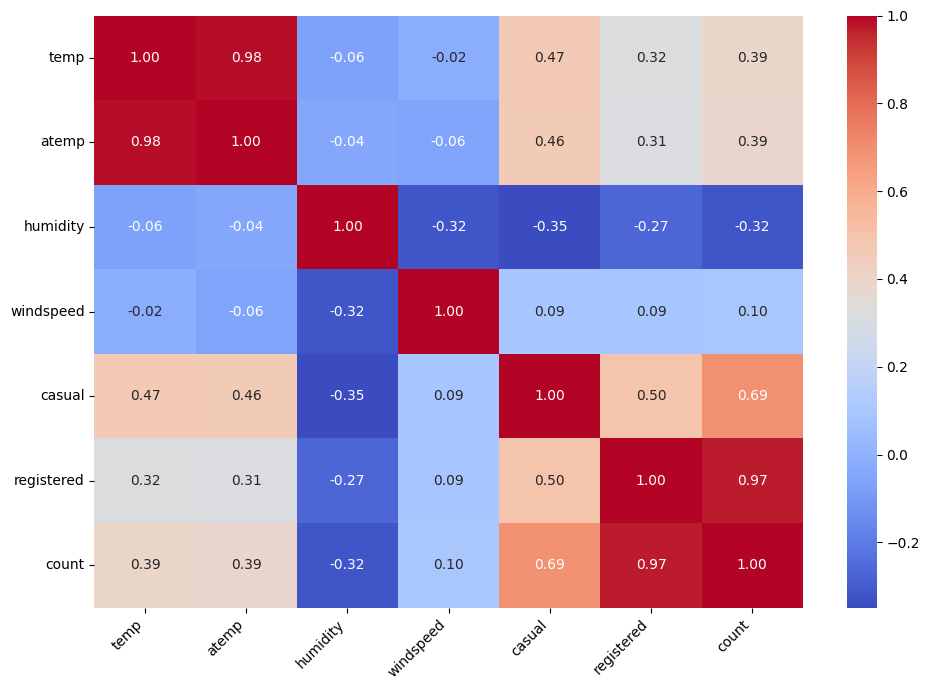

In [ ]:
continuous_cols = [
    'temp', 'atemp', 'humidity',
    'windspeed', 'casual', 'registered', 'count'
]

plt.figure(figsize=(10, 7))

sns.heatmap(
    df[continuous_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# My Analysis:

The heatmap shows that rental count has a strong positive correlation with registered users (0.97) and a moderate positive correlation with casual users (0.69). However, since registered and casual users are components of total rentals (count = casual + registered), these correlations are mathematically expected and should not be interpreted as independent predictive relationships. Temperature has a positive correlation (0.39), while humidity has a negative correlation (-0.32) with rental count. Temperature and feeling temperature also have a very strong positive correlation (0.98), which is expected because both represent related measures of temperature.

# Step -2: Statistical Analysis
# Part 1
# Working days v/s count

# Step 1: Establishing the relationship between the dependent variable count and the independent variable workingday

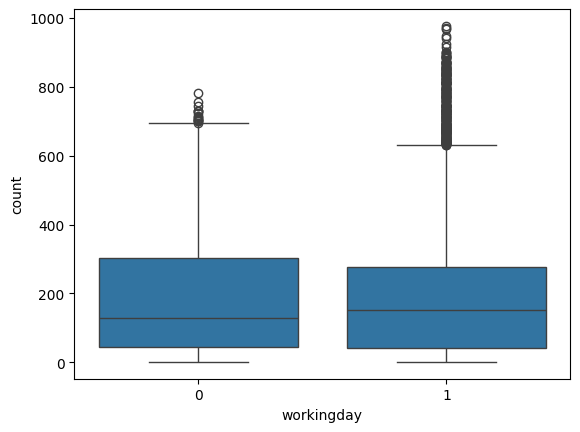

In [ ]:
sns.boxplot(x='workingday', y='count', data=df)
plt.show()

In [ ]:
df.groupby('workingday')['count'].agg(['mean', 'median']).reset_index()

,workingday,mean,median
0,0,188.506621,128.0
1,1,193.011873,151.0


# My Analysis:

The average rental count is slightly higher on working days (193.01) than on non-working days (188.51), with similar medians (151 vs 128). The boxplot shows considerable overlap, suggesting similar rental demand. An Independent Two-Sample t-test will be used to test whether the difference is significant.

# Step 2: Checking for normality of data

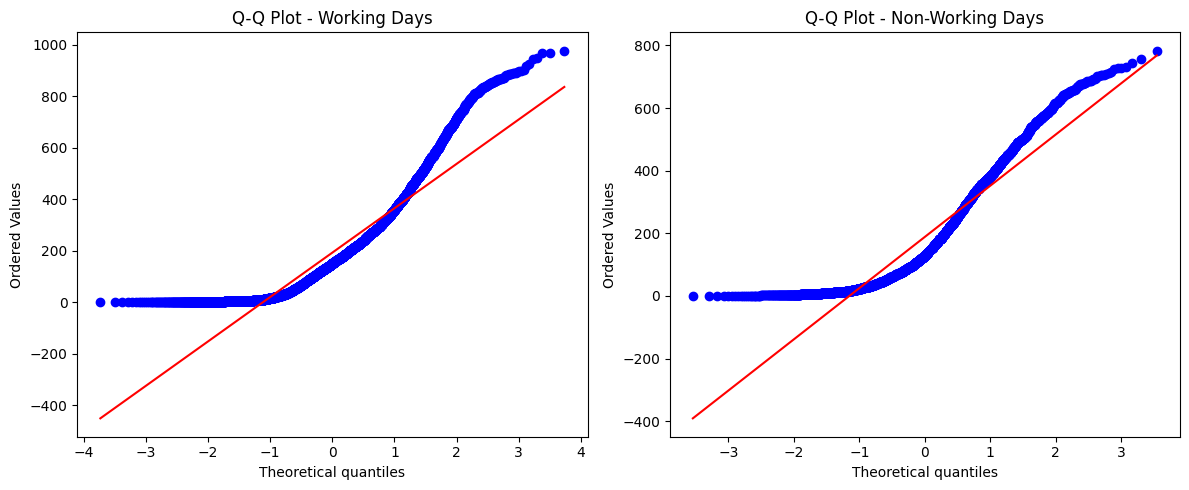

In [ ]:
import scipy.stats as stats # Importing necessary Library
working_day_counts = df[df['workingday'] == 1]['count']
non_working_day_counts = df[df['workingday'] == 0]['count']
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Working days
stats.probplot(working_day_counts, dist="norm", plot=axes[0])
axes[0].set_title("Q-Q Plot - Working Days")
# Non-working days
stats.probplot(non_working_day_counts, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q Plot - Non-Working Days")

plt.tight_layout()
plt.show()

# My Analysis:
The Q-Q plots for both working and non-working days show that the data points deviate considerably from the reference line, indicating that the rental count is not normally distributed. However, since the assignment instructs us to continue the analysis even when assumptions are not fully satisfied, I proceed with the statistical testing and consider this limitation while interpreting the results.

# Step3: Checking Equal Variance(Levene's Test)

In [ ]:
from scipy.stats import levene # Importing Necessary Library

In [ ]:
# Ho: Variances are equal
# Ha: Variances are not equal

levene_stat, p_value = levene(working_day_counts, non_working_day_counts)

print(p_value)

0.9437823280916695


In [ ]:
Alpha = 0.05 # 95% Confidence Level
if p_value < Alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

Fail to reject the null hypothesis


# My Analysis:
Levene's test gives a p-value of 0.9438, which is greater than 0.05. Therefore, we fail to reject H₀, indicating that the variances are equal across working and non-working days. The equal variance assumption is satisfied, so we can proceed with the Independent Two-Sample t-test.

# Step 4: Hypothesis testing (Bivariate Analysis)

# Independent Two-Sample t-test

In [ ]:
# Null Hypothesis(Ho): The mean number of rented bikes is the same on working and non-working days.

# Alternate Hypothesis(Ha): The mean number of rented bikes is different between working and non-working days.
from scipy.stats import ttest_ind # Importing the necessary libraries

In [ ]:
t_stat,pvalue = ttest_ind(working_day_counts, non_working_day_counts)
print("t-statistic:", t_stat)
print("p-value:", pvalue)

t-statistic: 1.2096277376026694
p-value: 0.22644804226361348


In [ ]:
Alpha = 0.05 # 95% Confidence Level
if pvalue < Alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

Fail to reject the null hypothesis


# My Analysis:
Although the sample mean rental count is slightly higher on working days (193.01) than on non-working days (188.51), the p-value of 0.2264 is greater than 0.05. Therefore, we fail to reject H₀ and conclude that there is not enough statistical evidence to say that the mean rental count differs between working and non-working days.

#Business Analysis:
The analysis suggests that rental demand is broadly similar on working and non-working days. Therefore, factors other than workingday may be more relevant in explaining variations in the number of electric cycles rented.

# Part 2
# Season V/S count

# Step 1: Establishing the relationship between the dependent variable count and the independent variable Season

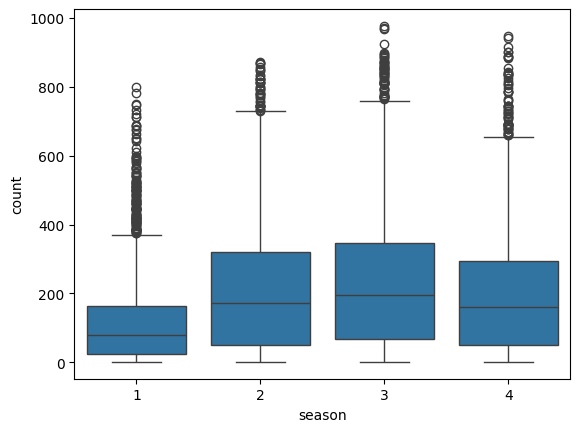

In [ ]:
sns.boxplot(x='season', y='count', data=df)
plt.show()

In [ ]:
df.groupby('season')['count'].agg(
    mean='mean',
    median='median')

,mean,median
season,,
1,116.343261,78.0
2,215.251372,172.0
3,234.417124,195.0
4,198.988296,161.0


#Season 1 → Spring
#Season 2 → Summer
#Season 3 → Fall
#Season 4 → Winter

# My Analysis:

The rental count varies across seasons. Fall has the highest average rental count (234.42), while Spring has the lowest (116.34). The median values show a similar pattern, suggesting that season may have a relationship with rental demand. A One-Way ANOVA will be used to determine whether these differences are statistically significant.

# Step 2: Checking for Normality of data

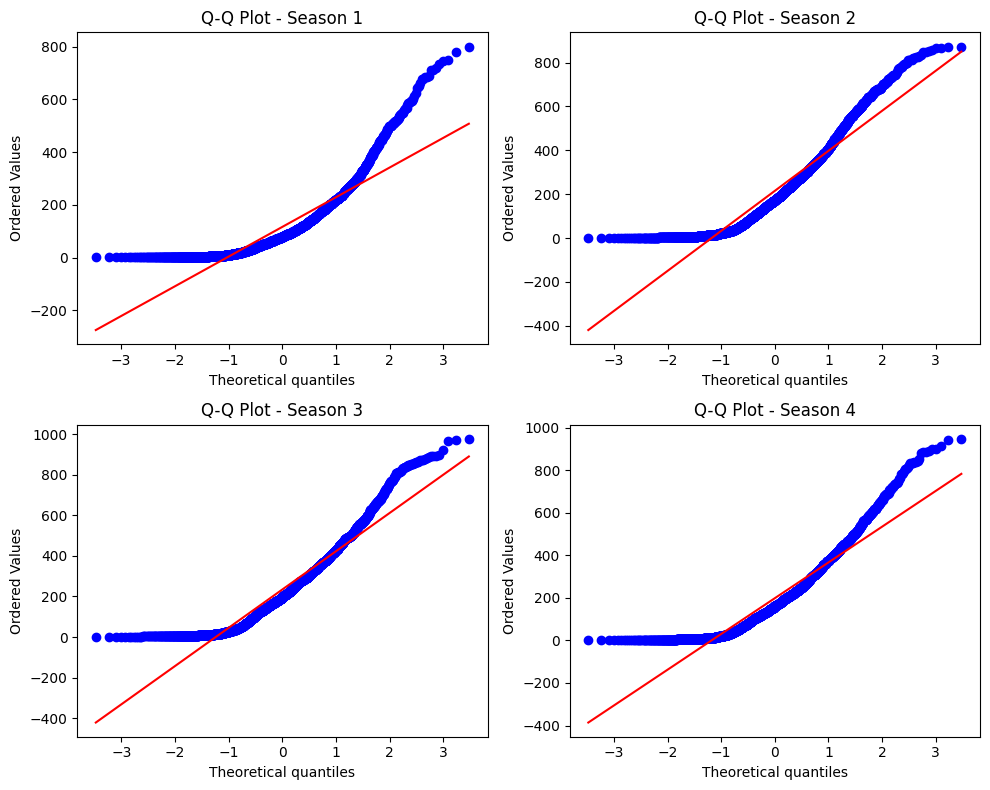

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for season, ax in zip([1, 2, 3, 4], axes.flatten()):
    stats.probplot(df[df['season'] == season]['count'], dist="norm", plot=ax)
    ax.set_title(f"Q-Q Plot - Season {season}")

plt.tight_layout()
plt.show()

# My Analysis:

The Q-Q plots for all four seasons show considerable deviation from the reference line, indicating that the rental count is not normally distributed within the seasons. As the normality assumption is not fully satisfied, we will proceed with the analysis as required and consider this limitation while interpreting the ANOVA results.

# Step 3: Checking for Variance (Levene's Test)

In [ ]:
# Ho: The variances of rental counts are equal across all seasons.
# Ha: The variances of rental counts are not equal across all seasons.

season1 = df[df['season'] == 1]['count']
season2 = df[df['season'] == 2]['count']
season3 = df[df['season'] == 3]['count']
season4 = df[df['season'] == 4]['count']

levene_stat, p_value = levene(
    season1,
    season2,
    season3,
    season4
)

print("Levene Statistic:", levene_stat)
print("p-value:", p_value)

Levene Statistic: 187.7706624026276
p-value: 1.0147116860043298e-118


In [ ]:
Alpha = 0.05 # 95% Confidence Level
if p_value < Alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

Reject the null hypothesis


# My Analysis:
Levene's test gives a p-value < 0.05, so we reject H₀, indicating that the variances are not equal across seasons. The equal variance assumption is not satisfied; however, as required by the assignment, we will proceed with the One-Way ANOVA and consider this limitation while interpreting the results.

# Step 4 :Hypothesis testing (Bivariate Analysis)

# One-Way ANOVA Test

In [ ]:
from scipy.stats import f_oneway # Importing necessary Library
# Ho: The mean rental count is the same across all seasons.
# Ha: At least one season has a different mean rental count.

f_stat, p_value = f_oneway(
    season1,
    season2,
    season3,
    season4
)

print("F-statistic:", f_stat)
print("p-value:", p_value)

F-statistic: 236.94671081032098
p-value: 6.164843386499654e-149


In [ ]:
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

Reject the null hypothesis


##Season 1 → Spring
##Season 2 → Summer
##Season 3 → Fall
##Season 4 → Winter

# My Analysis:

The One-Way ANOVA test gives an F-statistic of 236.95 and a p-value < 0.05. Therefore, we reject H₀, indicating that the mean rental counts are significantly different across seasons. This suggests that season has a significant relationship with rental demand.

# Business Insight:

Fall has the highest average rental demand (234.42), while Spring has the lowest (116.34). Yulu can plan higher bike availability and operational capacity during Fall, while adjusting resources during lower-demand seasons.

# Part 3

# Number of Cycles Rented vs Weather (Weather V/S Count)

# Step 1: Establishing relationship between the dependent variable count and independent variable weather

##Weather 1 → Clear, Few clouds, Partly cloudy
##Weather 2 → Mist + Cloudy
##Weather 3 → Light Snow, Light Rain + Thunderstorm
##Weather 4 → Heavy Rain, Ice Pellets, Thunderstorm + Mist, Snow + Fog

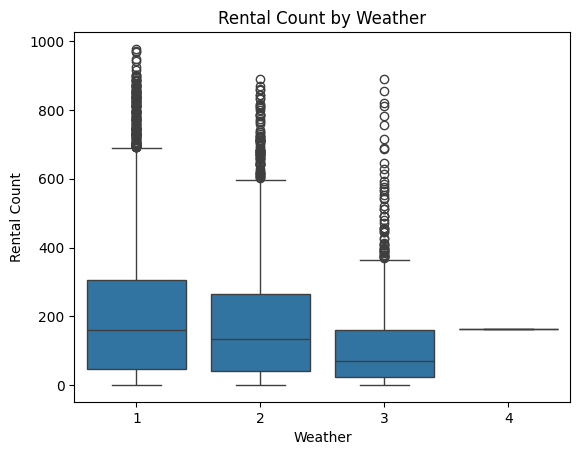

In [ ]:
sns.boxplot(x='weather', y='count', data=df)

plt.title('Rental Count by Weather')
plt.xlabel('Weather')
plt.ylabel('Rental Count')
plt.show()

In [ ]:
df.groupby('weather')['count'].agg(['mean', 'median'])

,mean,median
weather,,
1,205.236791,161.0
2,178.955540,134.0
3,118.846333,71.0
4,164.000000,164.0


# My Analysis:

Rental demand varies across weather conditions. Weather 1 has the highest average rental count among the well-represented weather categories (205.24), while Weather 3 has the lowest (118.85). Weather 4 has only one observation, so its average rental count (164.00) is not suitable for meaningful comparison. The median rental count is highest for Weather 1 (161) and lowest for Weather 3 (71). This suggests that weather conditions may be related to rental demand, which will be tested statistically using One-Way ANOVA.

# Step 2: Checking for Normality of data

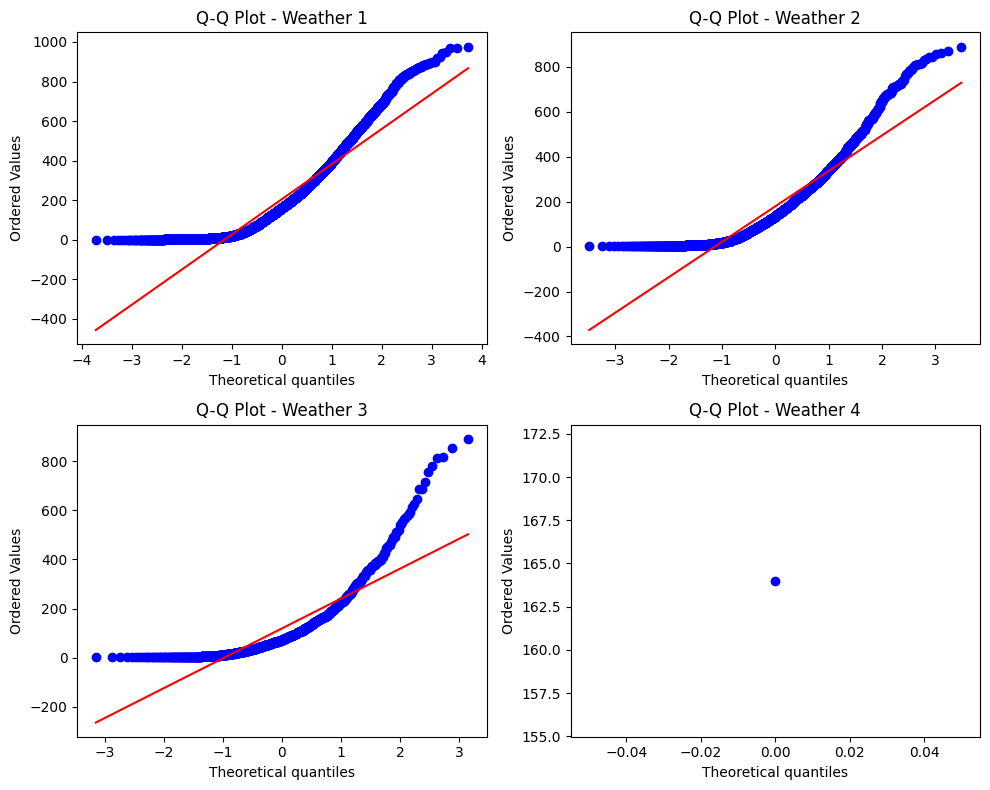

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for weather, ax in zip([1, 2, 3, 4], axes.flatten()):
    stats.probplot(
        df[df['weather'] == weather]['count'],
        dist="norm",
        plot=ax
    )
    ax.set_title(f"Q-Q Plot - Weather {weather}")

plt.tight_layout()
plt.show()

# My Analysis:

The Q-Q plots for Weather 1, 2, and 3 show considerable deviation from the reference line, indicating that rental counts are not normally distributed. Weather 4 has only one observation, so normality cannot be assessed for this group. Therefore, the normality assumption is not fully satisfied, but we will proceed with the analysis as required by the assignment.

# Step 3: Checking for Variance (Levene's Test)

In [ ]:
# Ho: The variances of rental counts are equal across all weather conditions.
# Ha: The variances of rental counts are not equal across all weather conditions.

weather1 = df[df['weather'] == 1]['count']
weather2 = df[df['weather'] == 2]['count']
weather3 = df[df['weather'] == 3]['count']
weather4 = df[df['weather'] == 4]['count']

levene_stat, p_value = levene(
    weather1,
    weather2,
    weather3,
    weather4
)

print("Levene Statistic:", levene_stat)
print("p-value:", p_value)

Levene Statistic: 54.85106195954556
p-value: 3.504937946833238e-35


In [ ]:
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

Reject the null hypothesis


# My Analysis:

Levene's test gives a p-value < 0.05, indicating that the variances of rental counts are not equal across weather conditions. Therefore, the equal variance assumption is not satisfied. However, as required by the assignment, we will proceed with the One-Way ANOVA and consider this limitation while interpreting the results.

# Step 4 :Hypothesis testing (Bivariate Analysis)

# One-Way ANOVA Test

In [ ]:
# Ho: The mean rental count is the same across all weather conditions.
# Ha: At least one weather condition has a different mean rental count.

f_stat, p_value = f_oneway(
    weather1,
    weather2,
    weather3,
    weather4
)

print("F-statistic:", f_stat)
print("p-value:", p_value)

F-statistic: 65.53024112793265
p-value: 5.482069475935669e-42


In [ ]:
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

Reject the null hypothesis


# My Analysis:

The One-Way ANOVA gives an F-statistic of 65.53 and a p-value < 0.05. Therefore, we reject H₀, indicating that the mean rental counts differ across weather conditions. However, Weather 4 contains only one observation, so comparisons involving this category should be interpreted with considerable caution.

# Business Insight:

Weather 1 has the highest average rental count (205.24), while Weather 3 has the lowest (118.85). Weather 4 is not considered for meaningful comparison because it contains only one observation. Yulu can use these demand differences to plan bike availability and operations according to weather conditions.

# Part 4

# Weather V/S Season

# Step 1: Establishing relationship between the categorical variables Season and Weather

In [ ]:
pd.crosstab(df['season'], df['weather']) # Creating a contingency table

weather,1,2,3,4
season,,,,
1,1759,715,211,1
2,1801,708,224,0
3,1930,604,199,0
4,1702,807,225,0


In [ ]:
pd.crosstab(
    df['season'],
    df['weather'],
    normalize='index'
) * 100    # Understanding the realtionship with percentages

weather,1,2,3,4
season,,,,
1,65.487714,26.619509,7.855547,0.03723
2,65.898280,25.905598,8.196121,0.00000
3,70.618368,22.100256,7.281376,0.00000
4,62.253109,29.517191,8.229700,0.00000


# My Analysis:

Season 3 has the highest proportion of clear weather (70.62%), while Season 4 has the highest proportion of mist/cloudy weather (29.52%). Overall, the distribution of weather conditions varies across seasons, suggesting a possible relationship between season and weather. A Chi-Square Test of Independence will be performed to determine whether this relationship is statistically significant.

# Step 2: Hypothesis Testing — Chi-Square Test of Independence

In [ ]:
# Ho: Season and Weather are independent.
# Ha: Season and Weather are dependent.

from scipy.stats import chi2_contingency #Importing necessary Library

contingency_table = pd.crosstab(df['season'], df['weather'])

chi2_stat, p_value, dof, expected = chi2_contingency(contingency_table)

print("Chi-square statistic:", chi2_stat)
print("p-value:", p_value)
print("Degrees of freedom:", dof)

Chi-square statistic: 49.158655596893624
p-value: 1.549925073686492e-07
Degrees of freedom: 9


In [ ]:
expected_df = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

expected_df

weather,1,2,3,4
season,,,,
1,1774.546390,699.258130,211.948742,0.246739
2,1805.597648,711.493845,215.657450,0.251056
3,1805.597648,711.493845,215.657450,0.251056
4,1806.258313,711.754180,215.736359,0.251148


In [ ]:
print("Minimum expected frequency:", expected.min())
print("Number of expected frequencies below 5:", (expected < 5).sum())

Minimum expected frequency: 0.24673893073672606
Number of expected frequencies below 5: 4


# Chi-Square Assumption Check

The Chi-Square test assumption regarding expected frequencies is not fully satisfied. There are 4 out of 16 cells (25%) with expected frequencies below 5, and the minimum expected frequency is approximately 0.25. Therefore, the expected-frequency assumption is violated. As instructed, the Chi-Square analysis is continued, but the result should be interpreted with caution.

In [ ]:
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

Reject the null hypothesis


# My Analysis:

The Chi-Square test gives a p-value < 0.05, so we reject H₀. There is statistically significant evidence of an association between season and weather. However, because the expected-frequency assumption is violated, this result should be interpreted with caution

# Business Insight:

Yulu can consider seasonal weather patterns when planning bike availability and operations. For example, clear weather is more common in Season 3 (70.62%), which may help inform availability planning during favorable weather periods.

# Business Recommendations
1. Optimize bike availability by season: Increase bike deployment during Fall (234.42 average rentals) and reduce excess inventory during Spring (116.34).
2. Use weather-based demand planning: Give higher priority to favorable weather conditions, where rental demand is higher, and adjust bike deployment during unfavorable conditions.
3. Combine season and weather for planning: The analysis indicates an association between season and weather; however, the Chi-Square expected-frequency assumption was violated, so this relationship should be interpreted with caution. Yulu can consider both factors together when planning demand and bike allocation.
4. Do not prioritize workingday in demand planning: Working and non-working days did not show a statistically significant difference in rental demand (p = 0.2264), so other factors may be more useful for demand planning.
5. Include temperature and humidity in forecasting: Temperature has a positive correlation (0.39) and humidity a negative correlation (-0.32) with rentals, so these variables can improve demand planning.